В качестве выбранного датасета выступает набор данных о пингвинах, находящийся по пути data/penguins.csv из лабораторной работы 3.

In [63]:
# Проделаем все операции по подготовки датасета в соответствии с описание в лабораторной работе 3
import pandas as pd
PATH = "data/penguins.csv"
df = pd.read_csv(PATH)
df = df.dropna().reset_index(drop=True)
display(df.head(5))
df.info()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
4,Adelie,Torgersen,39.3,20.6,190.0,3650.0,male,2007


<class 'pandas.DataFrame'>
RangeIndex: 333 entries, 0 to 332
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            333 non-null    str    
 1   island             333 non-null    str    
 2   bill_length_mm     333 non-null    float64
 3   bill_depth_mm      333 non-null    float64
 4   flipper_length_mm  333 non-null    float64
 5   body_mass_g        333 non-null    float64
 6   sex                333 non-null    str    
 7   year               333 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 20.9 KB


In [64]:
# Импортируем необходимые библиотеки
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [65]:
# так как StandartScaler не умеет работать со строками, то будем реализовывать кластеризацию только по числовым признакам кроме year
features = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g",
]

sc = StandardScaler()
X_sc = sc.fit_transform(df[features])
linked = linkage(X_sc, method = "ward")

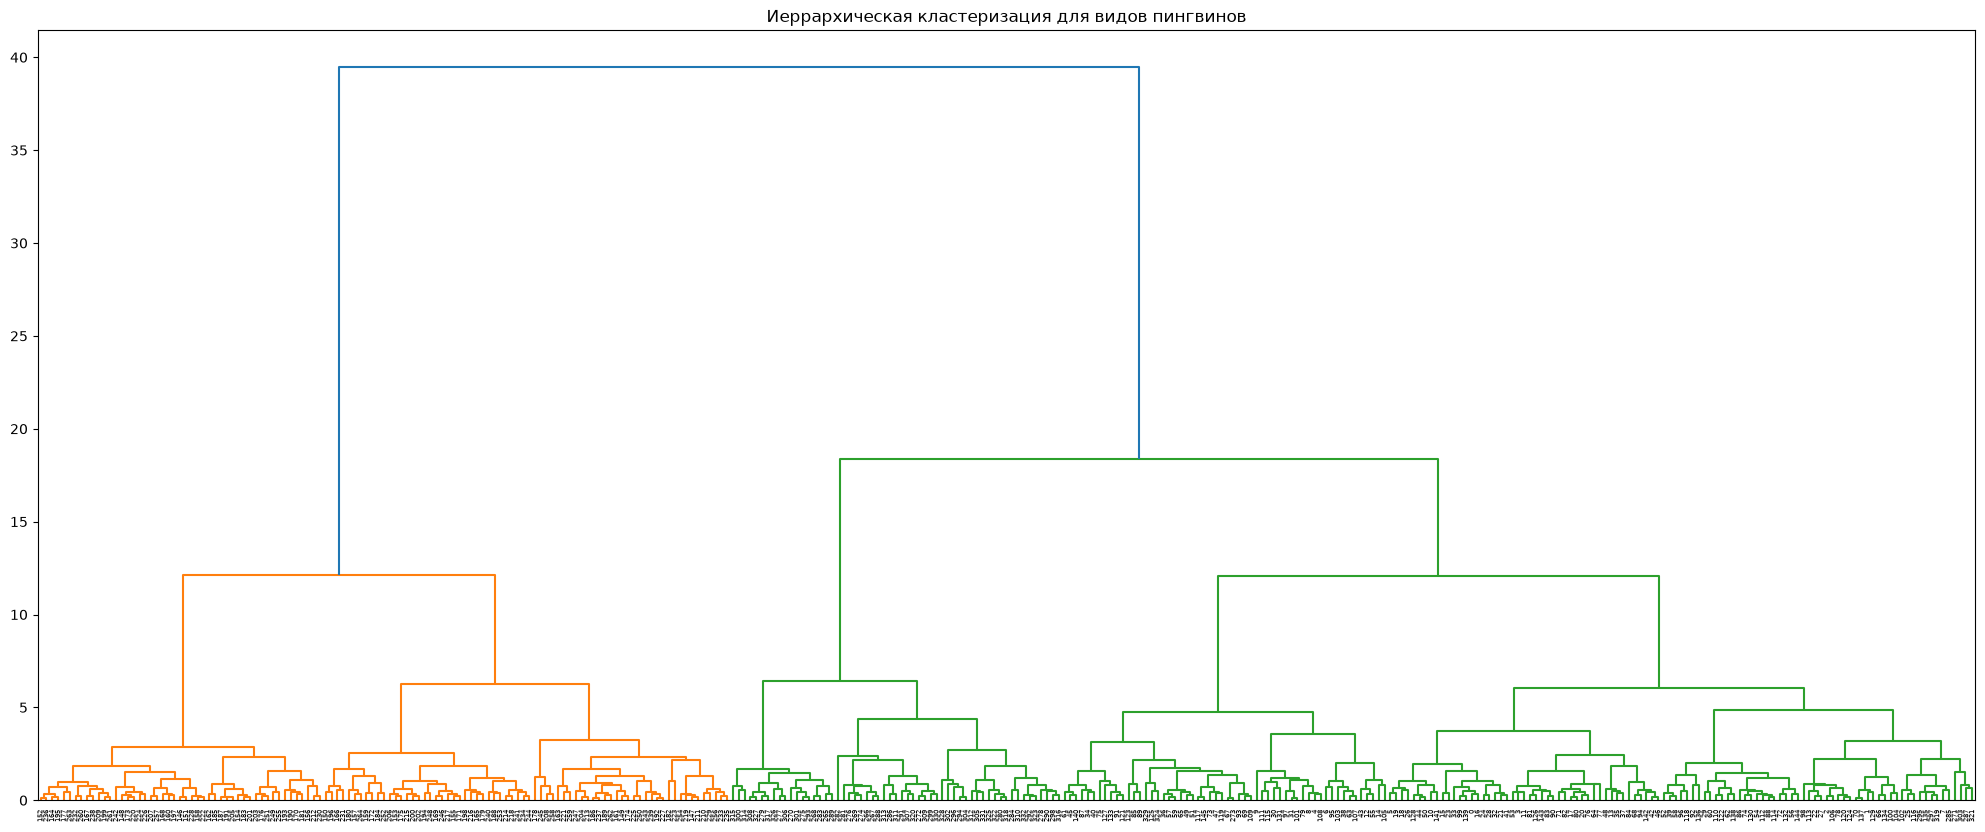

In [66]:
plt.figure(figsize=(25,10))
dendrogram(linked, orientation="top")
plt.title("Иеррархическая кластеризация для видов пингвинов")
plt.show()

На дендрограмме можно выделить три кластера, проведя горизонтальный срез на высоте около 15: он проходит выше объединений на высоте примерно 12 и ниже объединения на высоте 18,5. Поэтому для дальнейшего анализа примем гипотезу о наличии трёх кластеров. При этом наиболее крупный скачок расстояния наблюдается между 18,5 и 39,5 и поддерживает более общее разбиение на две группы; выбор трёх кластеров позволяет подробнее исследовать структуру данных.


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
Кластер,,,,
1,0.654758,-1.102707,1.162463,1.101211
2,1.054828,0.730767,-0.275940,-0.493739
3,-0.879245,0.570499,-0.780920,-0.655420


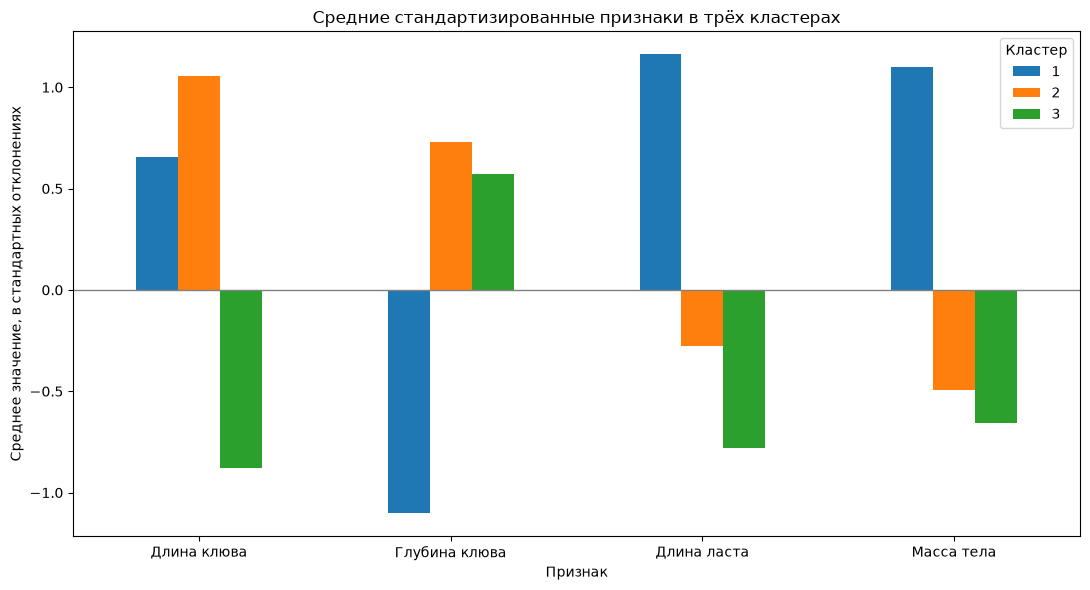

flipper_length_mm    1.943383
bill_length_mm       1.934073
bill_depth_mm        1.833474
body_mass_g          1.756631
Name: Размах средних (стандартизированный), dtype: float64

Три наиболее различающихся признака:
Длина ласта (flipper_length_mm): 1.943
Длина клюва (bill_length_mm): 1.934
Глубина клюва (bill_depth_mm): 1.833


In [67]:
# Оцениваем различия средних признаков для трёх кластеров, выбранных по дендрограмме
from scipy.cluster.hierarchy import fcluster

X_standardized = pd.DataFrame(
    StandardScaler().fit_transform(df[features]),
    columns=features,
    index=df.index,
)
linked_for_analysis = linkage(X_standardized, method="ward")
cluster_labels = fcluster(linked_for_analysis, t=3, criterion="maxclust")

cluster_means = X_standardized.groupby(cluster_labels).mean()
cluster_means.index.name = "Кластер"
display(cluster_means)

feature_names = {
    "bill_length_mm": "Длина клюва",
    "bill_depth_mm": "Глубина клюва",
    "flipper_length_mm": "Длина ласта",
    "body_mass_g": "Масса тела",
}
ax = cluster_means.rename(columns=feature_names).T.plot.bar(figsize=(11, 6))
ax.axhline(0, color="gray", linewidth=1)
ax.set_title("Средние стандартизированные признаки в трёх кластерах")
ax.legend(title="Кластер")
ax.set_xlabel("Признак")
ax.set_ylabel("Среднее значение, в стандартных отклонениях")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

# Для трёх кластеров сравниваем размах: максимум минус минимум средних.
# Чем он больше, тем сильнее признак различает полученные группы.
mean_difference = (cluster_means.max() - cluster_means.min()).sort_values(ascending=False)
display(mean_difference.rename("Размах средних (стандартизированный)"))
print("Три наиболее различающихся признака:")
for feature in mean_difference.head(3).index:
    print(f"{feature_names[feature]} ({feature}): {mean_difference[feature]:.3f}")


По графику средних стандартизированных значений трёх кластеров наиболее выраженные различия наблюдаются по длине ласта, длине клюва и глубине (толщине) клюва. Размах средних (максимальное среднее минус минимальное среди трёх кластеров) составляет приблизительно 1,943; 1,934 и 1,833 стандартного отклонения соответственно. Для массы тела размах меньше - около 1,757.

Первый кластер характеризуется наиболее длинными ластами, наибольшей массой тела и наименьшей глубиной клюва. У второго кластера самая большая средняя длина клюва и самая большая средняя глубина клюва. У третьего кластера самые короткие клювы и ласты и наименьшая средняя масса тела. Сравнение проводится после стандартизации, чтобы разные единицы измерения не искажали выводы. Такой анализ показывает, какие признаки сильнее различают уже полученные группы, но не является строгой оценкой причинного влияния признаков на кластеризацию.


Кластеризация методом k-средних проводится по тем же четырём физическим признакам после стандартизации. Число кластеров k = 3 выбрано в соответствии с гипотезой о трёх группах по дендрограмме.

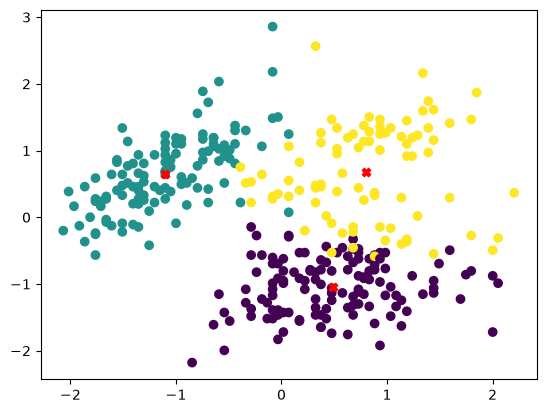

In [68]:
import numpy as np
from sklearn.cluster import KMeans

# Используем те же признаки и подготовленные данные
kmeans_scaler = StandardScaler()
sc_df = kmeans_scaler.fit_transform(df[features])
km = KMeans(n_clusters=3, random_state=42)
labels = km.fit_predict(sc_df)
centers = km.cluster_centers_

plt.scatter(sc_df[:,1], sc_df[:,0], c=labels)
plt.scatter(km.cluster_centers_[:,1], km.cluster_centers_[:,0], color="red", marker="X")


In [69]:
print("Координаты точек центроидов:", centers, sep="\n")
print("Евклидово расстояние между кластерами = ", np.linalg.norm(centers))

Координаты точек центроидов:
[[-1.04680889  0.48662566 -0.88169491 -0.7627539 ]
 [ 0.65475809 -1.10270671  1.16246305  1.10121078]
 [ 0.67202511  0.80526339 -0.28934658 -0.38410387]]
Евклидово расстояние между кластерами =  2.8691065980188317


Text(0, 0.5, '$J(C_k)$')

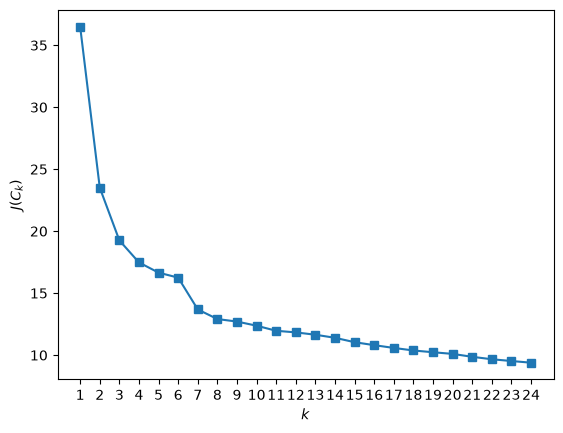

In [70]:
inertia = []
for k in range(1, 25):
    kmeans = KMeans(n_clusters=k, random_state=42).fit(sc_df)
    inertia.append(np.sqrt(kmeans.inertia_))

plt.plot(range(1, 25), inertia, marker="s")
plt.xticks(range(1, 25))
plt.xlabel("$k$")
plt.ylabel("$J(C_k)$")

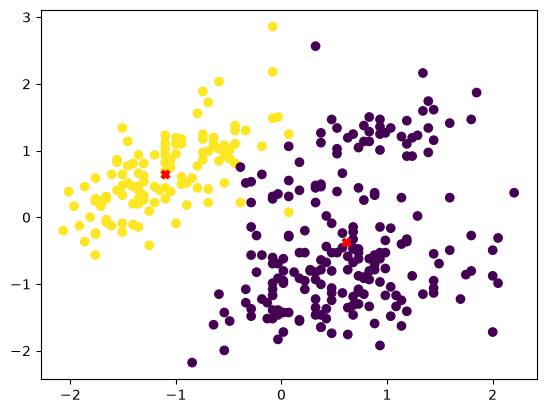

In [71]:
# Перестроим точечную диаграмму с новым значением числа кластеров = 2,
# полученным на основе анализа оптимального числа кластеров используя метод "локтя"

kmeans_scaler = StandardScaler()
sc_df = kmeans_scaler.fit_transform(df[features])
km = KMeans(n_clusters=2, random_state=42)
labels = km.fit_predict(sc_df)
centers = km.cluster_centers_

plt.scatter(sc_df[:,1], sc_df[:,0], c=labels)
plt.scatter(km.cluster_centers_[:,1], km.cluster_centers_[:,0], color="red", marker="X")

**Анализ итогового разбиения методом k-средних (k = 2)**

Анализируем последнее полученное разбиение. Для оценки значимости признаков используем размах их средних стандартизированных значений между кластерами. Это позволяет сравнивать миллиметры и граммы на общей шкале. Чем больше размах, тем сильнее признак различает полученные группы; такая оценка описывает различия групп, а не доказывает причинное влияние признака.

In [72]:
# Средние в исходных единицах и после стандартизации
# object_id - индекс в очищенном df, а не номер строки исходного CSV
final_objects = df.copy()
final_objects.insert(0, "object_id", df.index)
final_objects["cluster"] = labels  # Сохраняем номера кластеров

final_means = final_objects.groupby("cluster")[features].mean()
final_standardized = pd.DataFrame(sc_df, columns=features, index=df.index)
final_standardized["cluster"] = labels
final_means_z = final_standardized.groupby("cluster")[features].mean()

print("Количество объектов в каждом кластере:")
display(final_objects.groupby("cluster").size().rename("Количество объектов").to_frame())
print("Средние значения: длина и глубина клюва и длина ласта - мм, масса тела - г:")
display(final_means.round(2))
print("Средние стандартизированные значения:")
display(final_means_z.round(3))

final_feature_ranking = (
    (final_means_z.max() - final_means_z.min())
    .sort_values(ascending=False)
    .rename("Размах средних (стандартных отклонений)")
    .to_frame()
)
final_feature_ranking.insert(
    0, "Признак", [feature_names[f] for f in final_feature_ranking.index]
)
print("Ранжирование признаков по различию средних:")
display(final_feature_ranking.round(3))
final_top_features = final_feature_ranking.head(3).index.tolist()
print("Три наиболее значимых признака:", ", ".join(feature_names[f] for f in final_top_features))

Количество объектов в каждом кластере:


,Количество объектов
cluster,
0,214
1,119


Средние значения: длина и глубина клюва и длина ласта - мм, масса тела - г:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
cluster,,,,
0,42.00,18.37,191.92,3714.72
1,47.57,15.00,217.24,5092.44


Средние стандартизированные значения:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
cluster,,,,
0,-0.364,0.613,-0.646,-0.612
1,0.655,-1.103,1.162,1.101


Ранжирование признаков по различию средних:


,Признак,Размах средних (стандартных отклонений)
flipper_length_mm,Длина ласта,1.809
bill_depth_mm,Глубина клюва,1.716
body_mass_g,Масса тела,1.714
bill_length_mm,Длина клюва,1.019


Три наиболее значимых признака: Длина ласта, Глубина клюва, Масса тела


In [73]:
objects_by_cluster = {
    int(cluster): group.copy()
    for cluster, group in final_objects.groupby("cluster", sort=True)
}
for cluster, objects in objects_by_cluster.items():
    print(f"Кластер {cluster}: {len(objects)} объектов")
    print("Идентификаторы объектов:", objects["object_id"].tolist())

# Вид не использовался при обучении: сопоставляем его с готовыми кластерами
# только для интерпретации результата в предметной области.
print("Видовой состав кластеров:")
display(pd.crosstab(final_objects["cluster"], final_objects["species"]))

Кластер 0: 214 объектов
Идентификаторы объектов: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310, 311, 312, 313, 314, 315, 316, 317, 318, 319, 320, 321, 322, 323, 324, 325, 326, 327, 328, 329, 330, 

species,Adelie,Chinstrap,Gentoo
cluster,,,
0,146,68,0
1,0,0,119


**Интерпретация и условные названия кластеров**

Три признака, наиболее сильно различающие итоговые кластеры по размаху средних стандартизированных значений:

1. **Длина ласта** (flipper_length_mm) - размах **1,809** стандартного отклонения.
2. **Глубина клюва** (bill_depth_mm) - **1,716**.
3. **Масса тела** (body_mass_g) - **1,714**.

Для длины клюва размах составляет около **1,019**, поэтому она не вошла в первую тройку. Глубина клюва и масса тела дают практически одинаковые по величине различия.

**Кластер 0 - «Лёгкие пингвины с короткими ластами и глубоким клювом».** Включает 214 объектов: 146 пингвинов Адели (Adelie) и 68 антарктических пингвинов (Chinstrap). Средняя длина ласта - **191,92 мм**, глубина клюва - **18,37 мм**, масса тела - **3714,72 г**. По сравнению со вторым кластером это более лёгкие птицы с короткими ластами и более глубоким клювом. Средняя длина клюва - 42,00 мм. Таким образом, по выбранным физическим характеристикам два вида оказались объединены в одну группу.

**Кластер 1 - «Тяжёлые пингвины с длинными ластами и неглубоким клювом».** Включает 119 объектов, все относятся к папуанским пингвинам (Gentoo). Средняя длина ласта - **217,24 мм**, глубина клюва - **15,00 мм**, масса тела - **5092,44 г**. Для этой группы характерны длинные ласты, большая масса тела и меньшая глубина клюва. Средняя длина клюва - 47,57 мм.

Названия отражают прежде всего три наиболее различающихся признака. Все характеристики относительны к другой группе данного набора данных. Видовой состав служит дополнительной интерпретацией: столбец species не участвовал в кластеризации. Полный перечень объектов каждой группы приведён выше; номера кластеров являются условными метками модели.